In [4]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy

STEP 1. Classical Data
Age    : 25
Income : 280

STEP 2. Normalize
Input Feature
[0.25, 0.7]

STEP 3. Feature Map
     ┌──────────────────────────┐
q_0: ┤0                         ├
     │  ZZFeatureMap(x[0],x[1]) │
q_1: ┤1                         ├
     └──────────────────────────┘

STEP 4. Variational Circuit
     ┌──────────────────────────────────────┐
q_0: ┤0                                     ├
     │  RealAmplitudes(θ[0],θ[1],θ[2],θ[3]) │
q_1: ┤1                                     ├
     └──────────────────────────────────────┘

STEP 5. Compose Circuit
     ┌──────────────────────────┐┌──────────────────────────────────────┐
q_0: ┤0                         ├┤0                                     ├
     │  ZZFeatureMap(x[0],x[1]) ││  RealAmplitudes(θ[0],θ[1],θ[2],θ[3]) │
q_1: ┤1                         ├┤1                                     ├
     └──────────────────────────┘└──────────────────────────────────────┘

STEP 6. Parameters
x[0]
x[1]
θ[0]
θ[1]
θ[2]
θ[3]

STEP 7. Bin

/tmp/ipykernel_1060/3347130593.py:45: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=2, reps=1)
/tmp/ipykernel_1060/3347130593.py:55: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=2, reps=1)


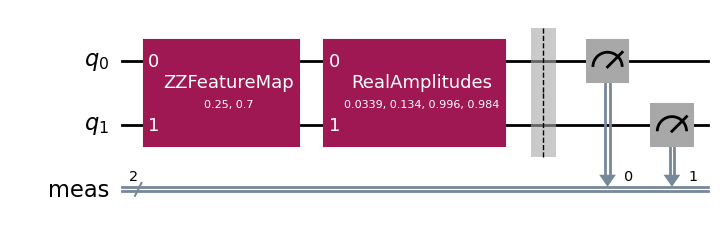


STEP 10. Simulation
Measurement Counts: {'01': 99, '11': 420, '10': 57, '00': 448}

STEP 11. Histogram


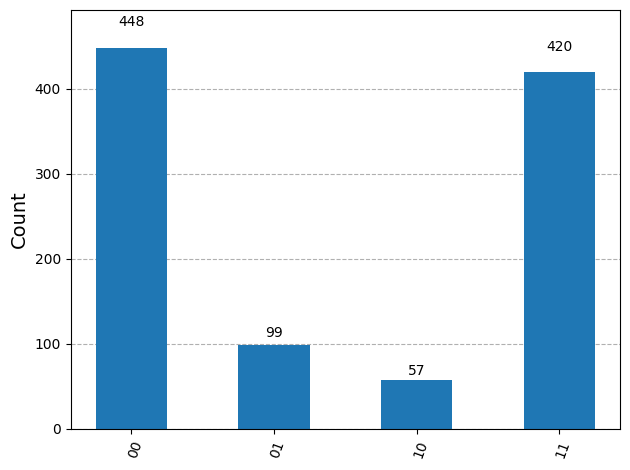


STEP 12. Prediction
Class 0 Probability : 0.493
Class 1 Probability : 0.507

Prediction Result
------------------------
Loan Denied

QML Workflow Finished Successfully!


In [5]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.visualization import plot_histogram

# =====================================================
# STEP 1. Classical Data 준비
# =====================================================
print("=" * 60)
print("STEP 1. Classical Data")
print("=" * 60)

age = 25
income = 280

print(f"Age    : {age}")
print(f"Income : {income}")

# =====================================================
# STEP 2. Feature 정규화
# =====================================================
print("\n" + "=" * 60)
print("STEP 2. Normalize")
print("=" * 60)

x1 = age / 100
x2 = income / 400
x = [x1, x2]

print("Input Feature")
print(x)

# =====================================================
# STEP 3. Feature Map 생성
# =====================================================
print("\n" + "=" * 60)
print("STEP 3. Feature Map")
print("=" * 60)

feature_map = ZZFeatureMap(feature_dimension=2, reps=1)
print(feature_map)  # 텍스트 회로 출력

# =====================================================
# STEP 4. Variational Circuit 생성
# =====================================================
print("\n" + "=" * 60)
print("STEP 4. Variational Circuit")
print("=" * 60)

ansatz = RealAmplitudes(num_qubits=2, reps=1)
print(ansatz)  # 텍스트 회로 출력

# =====================================================
# STEP 5. Pipeline 결합
# =====================================================
print("\n" + "=" * 60)
print("STEP 5. Compose Circuit")
print("=" * 60)

qml_circuit = feature_map.compose(ansatz)
print(qml_circuit)  # 결합된 텍스트 회로 출력

# =====================================================
# STEP 6. Parameter 확인
# =====================================================
print("\n" + "=" * 60)
print("STEP 6. Parameters")
print("=" * 60)

for p in qml_circuit.parameters:
    print(p)

# =====================================================
# STEP 7. Parameter Binding
# =====================================================
print("\n" + "=" * 60)
print("STEP 7. Bind Parameters")
print("=" * 60)

parameter_values = {}
fm_params = list(feature_map.parameters)
ansatz_params = list(ansatz.parameters)

for i, p in enumerate(fm_params):
    if i < len(x):
        parameter_values[p] = x[i]

for p in ansatz_params:
    parameter_values[p] = np.random.random()

bound_circuit = qml_circuit.assign_parameters(parameter_values)
print("파라미터 바인딩 완료 (텍스트 생략)")

# =====================================================
# STEP 8. Measurement 추가
# =====================================================
print("\n" + "=" * 60)
print("STEP 8. Measurement")
print("=" * 60)

bound_circuit.measure_all()
print("측정(Measurement) 연산이 추가되었습니다.")
print(bound_circuit)  # 측정 게이트가 포함된 회로 텍스트 출력

# =====================================================
# STEP 9. Circuit Draw (그래프 시각화)
# =====================================================
print("\n" + "=" * 60)
print("STEP 9. Circuit Draw")
print("=" * 60)

fig_circuit = bound_circuit.draw("mpl")
display(fig_circuit)

# =====================================================
# STEP 10. Simulation
# =====================================================
print("\n" + "=" * 60)
print("STEP 10. Simulation")
print("=" * 60)

simulator = AerSimulator()
compiled = transpile(bound_circuit, simulator)
job = simulator.run(compiled, shots=1024)
result = job.result()
counts = result.get_counts()

print("Measurement Counts:", counts)

# =====================================================
# STEP 11. Histogram (그래프 시각화)
# =====================================================
print("\n" + "=" * 60)
print("STEP 11. Histogram")
print("=" * 60)

fig_hist = plot_histogram(counts)
display(fig_hist)

# =====================================================
# STEP 12. Prediction
# =====================================================
print("\n" + "=" * 60)
print("STEP 12. Prediction")
print("=" * 60)

total_shots = 1024
zero_probability = sum(counts.get(k, 0) for k in counts if k.endswith('0')) / total_shots
one_probability = sum(counts.get(k, 0) for k in counts if k.endswith('1')) / total_shots

print(f"Class 0 Probability : {zero_probability:.3f}")
print(f"Class 1 Probability : {one_probability:.3f}")

if zero_probability > one_probability:
    prediction = "Loan Approved"
else:
    prediction = "Loan Denied"

print("\nPrediction Result")
print("------------------------")
print(prediction)

print("\n" + "=" * 60)
print("QML Workflow Finished Successfully!")
print("=" * 60)